# Joint Significance Testing with the Wald Test

*Notebook 3 of 3 · Automotive / fuel economy*

The first two notebooks used logistic regression. This one covers a question that comes up in every model: **which predictors can we safely drop?** It uses the classic `mtcars` dataset and an ordinary least squares (OLS) regression to show why a *joint* test is needed when predictors are correlated.

> **Scope note.** The Wald test is demonstrated on an OLS model here. The same logic applies to logistic regression, where the Wald statistic tests whether coefficients (and so odds ratios) differ from zero.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             roc_curve, roc_auc_score, precision_recall_curve)

## Step 1 — Industry Objective

**Industry Context:**Automotive Engineering / Fuel Economy Analysis

**Objective:**Determine which engine characteristics genuinely drive fuel economy (mpg),
so engineering effort and future data collection focus only on variables that matter.

**Research Questions:**
- **RQ1:**Do displacement, carburettors, horsepower and cylinders jointly predict mpg?
- **RQ2:**Can `hp` and `cyl` be **dropped simultaneously**without significantly worsening
  model fit?
- **RQ3:**What is the most parsimonious model that retains predictive power?

### What is the Wald Test?
The Wald test assesses whether one or more coefficients are **jointly equal to zero**.

> **W = (β̂ − β₀)² / Var(β̂)**

- **H₀:**the tested coefficients are all zero (the variables add nothing)
- **H₁:**at least one is non-zero
- **p ≥ 0.05**→ fail to reject H₀ → the variables **can be dropped**
- **p < 0.05**→ reject H₀ → at least one variable **must be retained**

**Why not just read individual p-values?**Individual t-tests examine one coefficient at a
time. When predictors are correlated, each may look insignificant alone while being jointly
significant. **The Wald test evaluates them together**, which is the correct approach.

## Step 2 — Understand the Data (Descriptive Analytics)

> **Correction to the original notebook:**it used only **8 of the 32 mtcars rows**.
> With 4 predictors that leaves just 3 residual degrees of freedom — far too few for a
> trustworthy test. The **full 32-row dataset**is used here, which is why the p-value
> differs from the original.

In [2]:
import io
mtcars_data = """model,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
Mazda RX4,21,6,160,110,3.9,2.62,16.46,0,1,4,4
Mazda RX4 Wag,21,6,160,110,3.9,2.875,17.02,0,1,4,4
Datsun 710,22.8,4,108,93,3.85,2.32,18.61,1,1,4,1
Hornet 4 Drive,21.4,6,258,110,3.08,3.215,19.44,1,0,3,1
Hornet Sportabout,18.7,8,360,175,3.15,3.44,17.02,0,0,3,2
Valiant,18.1,6,225,105,2.76,3.46,20.22,1,0,3,1
Duster 360,14.3,8,360,245,3.21,3.57,15.84,0,0,3,4
Merc 240D,24.4,4,146.7,62,3.69,3.19,20,1,0,4,2
Merc 230,22.8,4,140.8,95,3.92,3.15,22.9,1,0,4,2
Merc 280,19.2,6,167.6,123,3.92,3.44,18.3,1,0,4,4
Merc 280C,17.8,6,167.6,123,3.92,3.44,18.9,1,0,4,4
Merc 450SE,16.4,8,275.8,180,3.07,4.07,17.4,0,0,3,3
Merc 450SL,17.3,8,275.8,180,3.07,3.73,17.6,0,0,3,3
Merc 450SLC,15.2,8,275.8,180,3.07,3.78,18,0,0,3,3
Cadillac Fleetwood,10.4,8,472,205,2.93,5.25,17.98,0,0,3,4
Lincoln Continental,10.4,8,460,215,3,5.424,17.82,0,0,3,4
Chrysler Imperial,14.7,8,440,230,3.23,5.345,17.42,0,0,3,4
Fiat 128,32.4,4,78.7,66,4.08,2.2,19.47,1,1,4,1
Honda Civic,30.4,4,75.7,52,4.93,1.615,18.52,1,1,4,2
Toyota Corolla,33.9,4,71.1,65,4.22,1.835,19.9,1,1,4,1
Toyota Corona,21.5,4,120.1,97,3.7,2.465,20.01,1,0,3,1
Dodge Challenger,15.5,8,318,150,2.76,3.52,16.87,0,0,3,2
AMC Javelin,15.2,8,304,150,3.15,3.435,17.3,0,0,3,2
Camaro Z28,13.3,8,350,245,3.73,3.84,15.41,0,0,3,4
Pontiac Firebird,19.2,8,400,175,3.08,3.845,17.05,0,0,3,2
Fiat X1-9,27.3,4,79,66,4.08,1.935,18.9,1,1,4,1
Porsche 914-2,26,4,120.3,91,4.43,2.14,16.7,0,1,5,2
Lotus Europa,30.4,4,95.1,113,3.77,1.513,16.9,1,1,5,2
Ford Pantera L,15.8,8,351,264,4.22,3.17,14.5,0,1,5,4
Ferrari Dino,19.7,6,145,175,3.62,2.77,15.5,0,1,5,6
Maserati Bora,15,8,301,335,3.54,3.57,14.6,0,1,5,8
Volvo 142E,21.4,4,121,109,4.11,2.78,18.6,1,1,4,2"""

df = pd.read_csv(io.StringIO(mtcars_data), sep=",")
print("Dataset shape:", df.shape, " <- full 32 rows (original used only 8)")
df.head()

Dataset shape: (32, 12)  <- full 32 rows (original used only 8)


,model,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
0,Mazda RX4,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4
1,Mazda RX4 Wag,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4
2,Datsun 710,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1
3,Hornet 4 Drive,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1
4,Hornet Sportabout,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2


In [3]:
df[['mpg','disp','carb','hp','cyl']].describe().round(2)

,mpg,disp,carb,hp,cyl
count,32.00,32.00,32.00,32.00,32.00
mean,20.09,230.72,2.81,146.69,6.19
std,6.03,123.94,1.62,68.56,1.79
min,10.40,71.10,1.00,52.00,4.00
25%,15.42,120.82,2.00,96.50,4.00
50%,19.20,196.30,2.00,123.00,6.00
75%,22.80,326.00,4.00,180.00,8.00
max,33.90,472.00,8.00,335.00,8.00


**Statistical Interpretation — mtcars:**

| Variable | Mean | SD | Min | Max | Insight |
|----------|------|----|-----|-----|---------|
| **mpg**(DV) | ~20.1 | ~6.0 | 10.4 | 33.9 | Wide spread — plenty of variance to explain |
| **disp**| ~230.7 | ~123.9 | 71.1 | 472 | Engine displacement (cu in) |
| **carb**| ~2.8 | ~1.6 | 1 | 8 | Number of carburettors |
| **hp**| ~146.7 | ~68.6 | 52 | 335 | Gross horsepower |
| **cyl**| ~6.2 | ~1.8 | 4 | 8 | Cylinders (4, 6 or 8) |

**Key observation:**`disp`, `hp` and `cyl` all measure **engine size in different ways**—
a bigger engine has more displacement, more power and more cylinders. This makes severe
**multicollinearity**almost certain, and multicollinearity is exactly what makes individual
t-tests unreliable and the **joint Wald test**necessary.

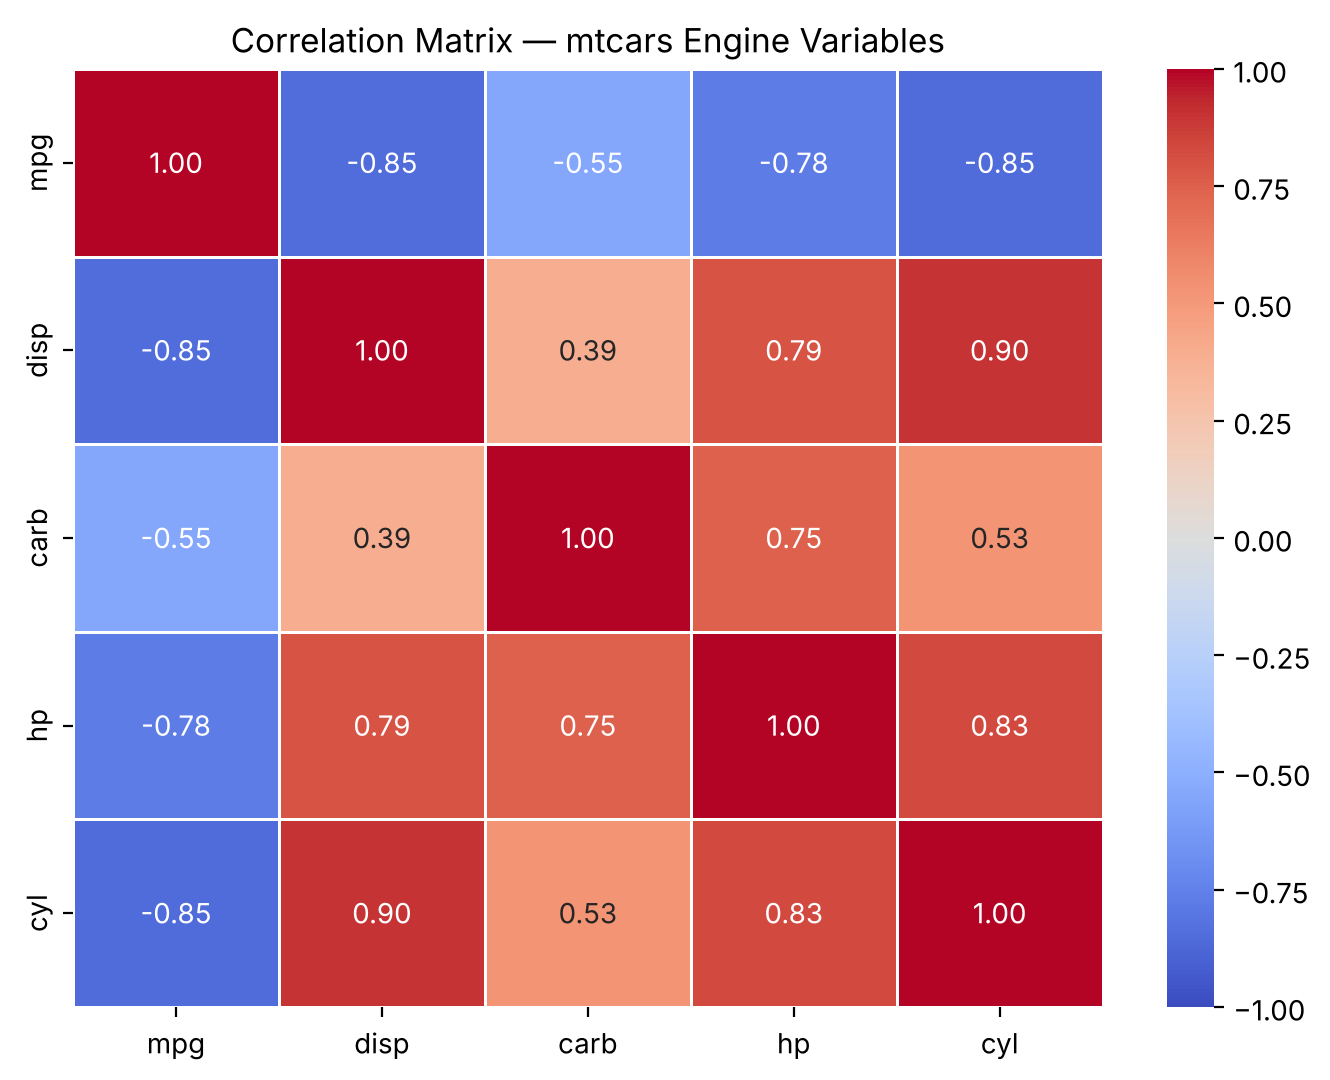

Correlation of predictors with each other:
       disp     hp    cyl
disp  1.000  0.791  0.902
hp    0.791  1.000  0.832
cyl   0.902  0.832  1.000


In [4]:
# Correlation matrix confirms the multicollinearity suspicion
corr = df[['mpg','disp','carb','hp','cyl']].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.5, ax=ax)
ax.set_title('Correlation Matrix — mtcars Engine Variables', fontsize=12)
plt.tight_layout(); plt.show()

print("Correlation of predictors with each other:")
print(corr.loc[['disp','hp','cyl'], ['disp','hp','cyl']].round(3))

**Reading the correlation matrix**

- `disp`, `hp` and `cyl` are strongly correlated with each other (r between 0.79 and 0.90). They are three different measures of engine size.
- All three correlate strongly and negatively with `mpg`: bigger engines are less efficient.
- This is the justification for a joint test. With predictors this collinear, each can look insignificant on its own while the group still matters.

## Step 3 — Data Cleaning

In [5]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print(f"\nObservations: {df.shape[0]}")
print(f"Predictors in model: 4  ->  residual df = {df.shape[0]-5}")
print("\nOriginal notebook used 8 rows -> residual df = 3 (unreliable).")
print("Full 32 rows give df = 27, which supports a trustworthy Wald test.")

Missing values: 0
Duplicate rows: 0

Observations: 32
Predictors in model: 4  ->  residual df = 27

Original notebook used 8 rows -> residual df = 3 (unreliable).
Full 32 rows give df = 27, which supports a trustworthy Wald test.


## Step 4 — Identify DV (Target) & IVs (Features)

| Role | Variable | Type | Rationale |
|------|----------|------|-----------|
| **DV (Target)**| `mpg` | Continuous | Fuel economy — the outcome to explain |
| **IV**| `disp` | Continuous | Displacement (cu in) |
| **IV**| `carb` | Count | Number of carburettors |
| **IV — tested**| `hp` | Continuous | **Candidate for removal**|
| **IV — tested**| `cyl` | Count | **Candidate for removal**|

The Wald test will evaluate **`hp` and `cyl` jointly**— not one at a time.

## Step 5 — Regression Analysis & Wald Test

In [6]:
# Fit the full model
results_ols = smf.ols('mpg ~ disp + carb + hp + cyl', data=df).fit()
print(results_ols.summary())

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.788
Model:                            OLS   Adj. R-squared:                  0.757
Method:                 Least Squares   F-statistic:                     25.09
Date:                Thu, 19 Nov 2026   Prob (F-statistic):           9.35e-09
Time:                        16:01:41   Log-Likelihood:                -77.558
No. Observations:                  32   AIC:                             165.1
Df Residuals:                      27   BIC:                             172.4
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     34.0216      2.523     13.482      0.0

In [7]:
# Wald test: are hp AND cyl jointly zero?
wald = results_ols.wald_test('(hp = 0, cyl = 0)', scalar=True)
print("Wald Test — H0: coefficients of hp AND cyl are both zero")
print(wald)
print(f"\np-value = {float(wald.pvalue):.4f}")

if float(wald.pvalue) >= 0.05:
    print("\np >= 0.05 -> FAIL TO REJECT H0")
    print("hp and cyl can be dropped without significantly worsening the model.")
else:
    print("\np < 0.05 -> REJECT H0 -> at least one must be retained.")

Wald Test — H0: coefficients of hp AND cyl are both zero
<F test: F=0.9112542943212392, p=0.41403001184235166, df_denom=27, df_num=2>

p-value = 0.4140

p >= 0.05 -> FAIL TO REJECT H0
hp and cyl can be dropped without significantly worsening the model.


In [8]:
# Verify by actually fitting the reduced model
reduced = smf.ols('mpg ~ disp + carb', data=df).fit()

print(f"{'Model':<22} {'R-squared':>10} {'Adj R2':>10} {'AIC':>9}")
print("-" * 54)
print(f"{'Full (4 predictors)':<22} {results_ols.rsquared:>10.4f} "
      f"{results_ols.rsquared_adj:>10.4f} {results_ols.aic:>9.2f}")
print(f"{'Reduced (2 predictors)':<22} {reduced.rsquared:>10.4f} "
      f"{reduced.rsquared_adj:>10.4f} {reduced.aic:>9.2f}")
print(f"\nR-squared lost by dropping hp and cyl: "
      f"{results_ols.rsquared - reduced.rsquared:.4f}")
print("A negligible loss confirms the Wald test conclusion.")

Model                   R-squared     Adj R2       AIC
------------------------------------------------------
Full (4 predictors)        0.7880     0.7566    165.12
Reduced (2 predictors)     0.7737     0.7581    163.21

R-squared lost by dropping hp and cyl: 0.0143
A negligible loss confirms the Wald test conclusion.


**Reading the regression and Wald test results**

### A. Full model

| Metric | Value | Reading |
|--------|-------|---------|
| R² | 0.788 | The four predictors explain about 79% of the variation in mpg |
| Adjusted R² | 0.757 | Penalised for the number of predictors; still strong |
| F-statistic p-value | 9.35 × 10⁻⁹ | The model is highly significant overall |
| Condition number | ≈ 1,510 | High: a warning sign for multicollinearity |

### B. Individual coefficients

| Variable | Coef | p-value | Significant at 5%? |
|----------|------|---------|:------------:|
| Intercept | 34.02 | < 0.001 | Yes |
| disp | −0.027 | 0.025 | Yes |
| carb | −0.927 | 0.121 | No |
| hp | +0.009 | 0.655 | No |
| cyl | −1.049 | 0.192 | No |

`hp` has a **positive** coefficient, implying that more horsepower improves mpg, which makes no mechanical sense. It is a classic symptom of multicollinearity: with `disp` and `cyl` already capturing engine size, the leftover `hp` effect is unstable and can flip sign.

### C. The Wald test

| | Value |
|---|---|
| H₀ | coef(hp) = 0 **and** coef(cyl) = 0 |
| F-statistic | 0.911 |
| p-value | **0.414** |
| Decision | p ≥ 0.05, so fail to reject H₀ |

`hp` and `cyl` can be dropped together without significantly worsening the fit. The reduced model confirms it: R² falls only from 0.788 to 0.774, and adjusted R² actually *rises* slightly (0.757 to 0.758).

**Why the joint test matters:** the individual p-values already hinted that these variables were weak, but only the joint test rules out the possibility that they matter as a group despite looking weak one by one. Multicollinearity is what sets that trap.

## Step 6 — Visualisation with Interpretation

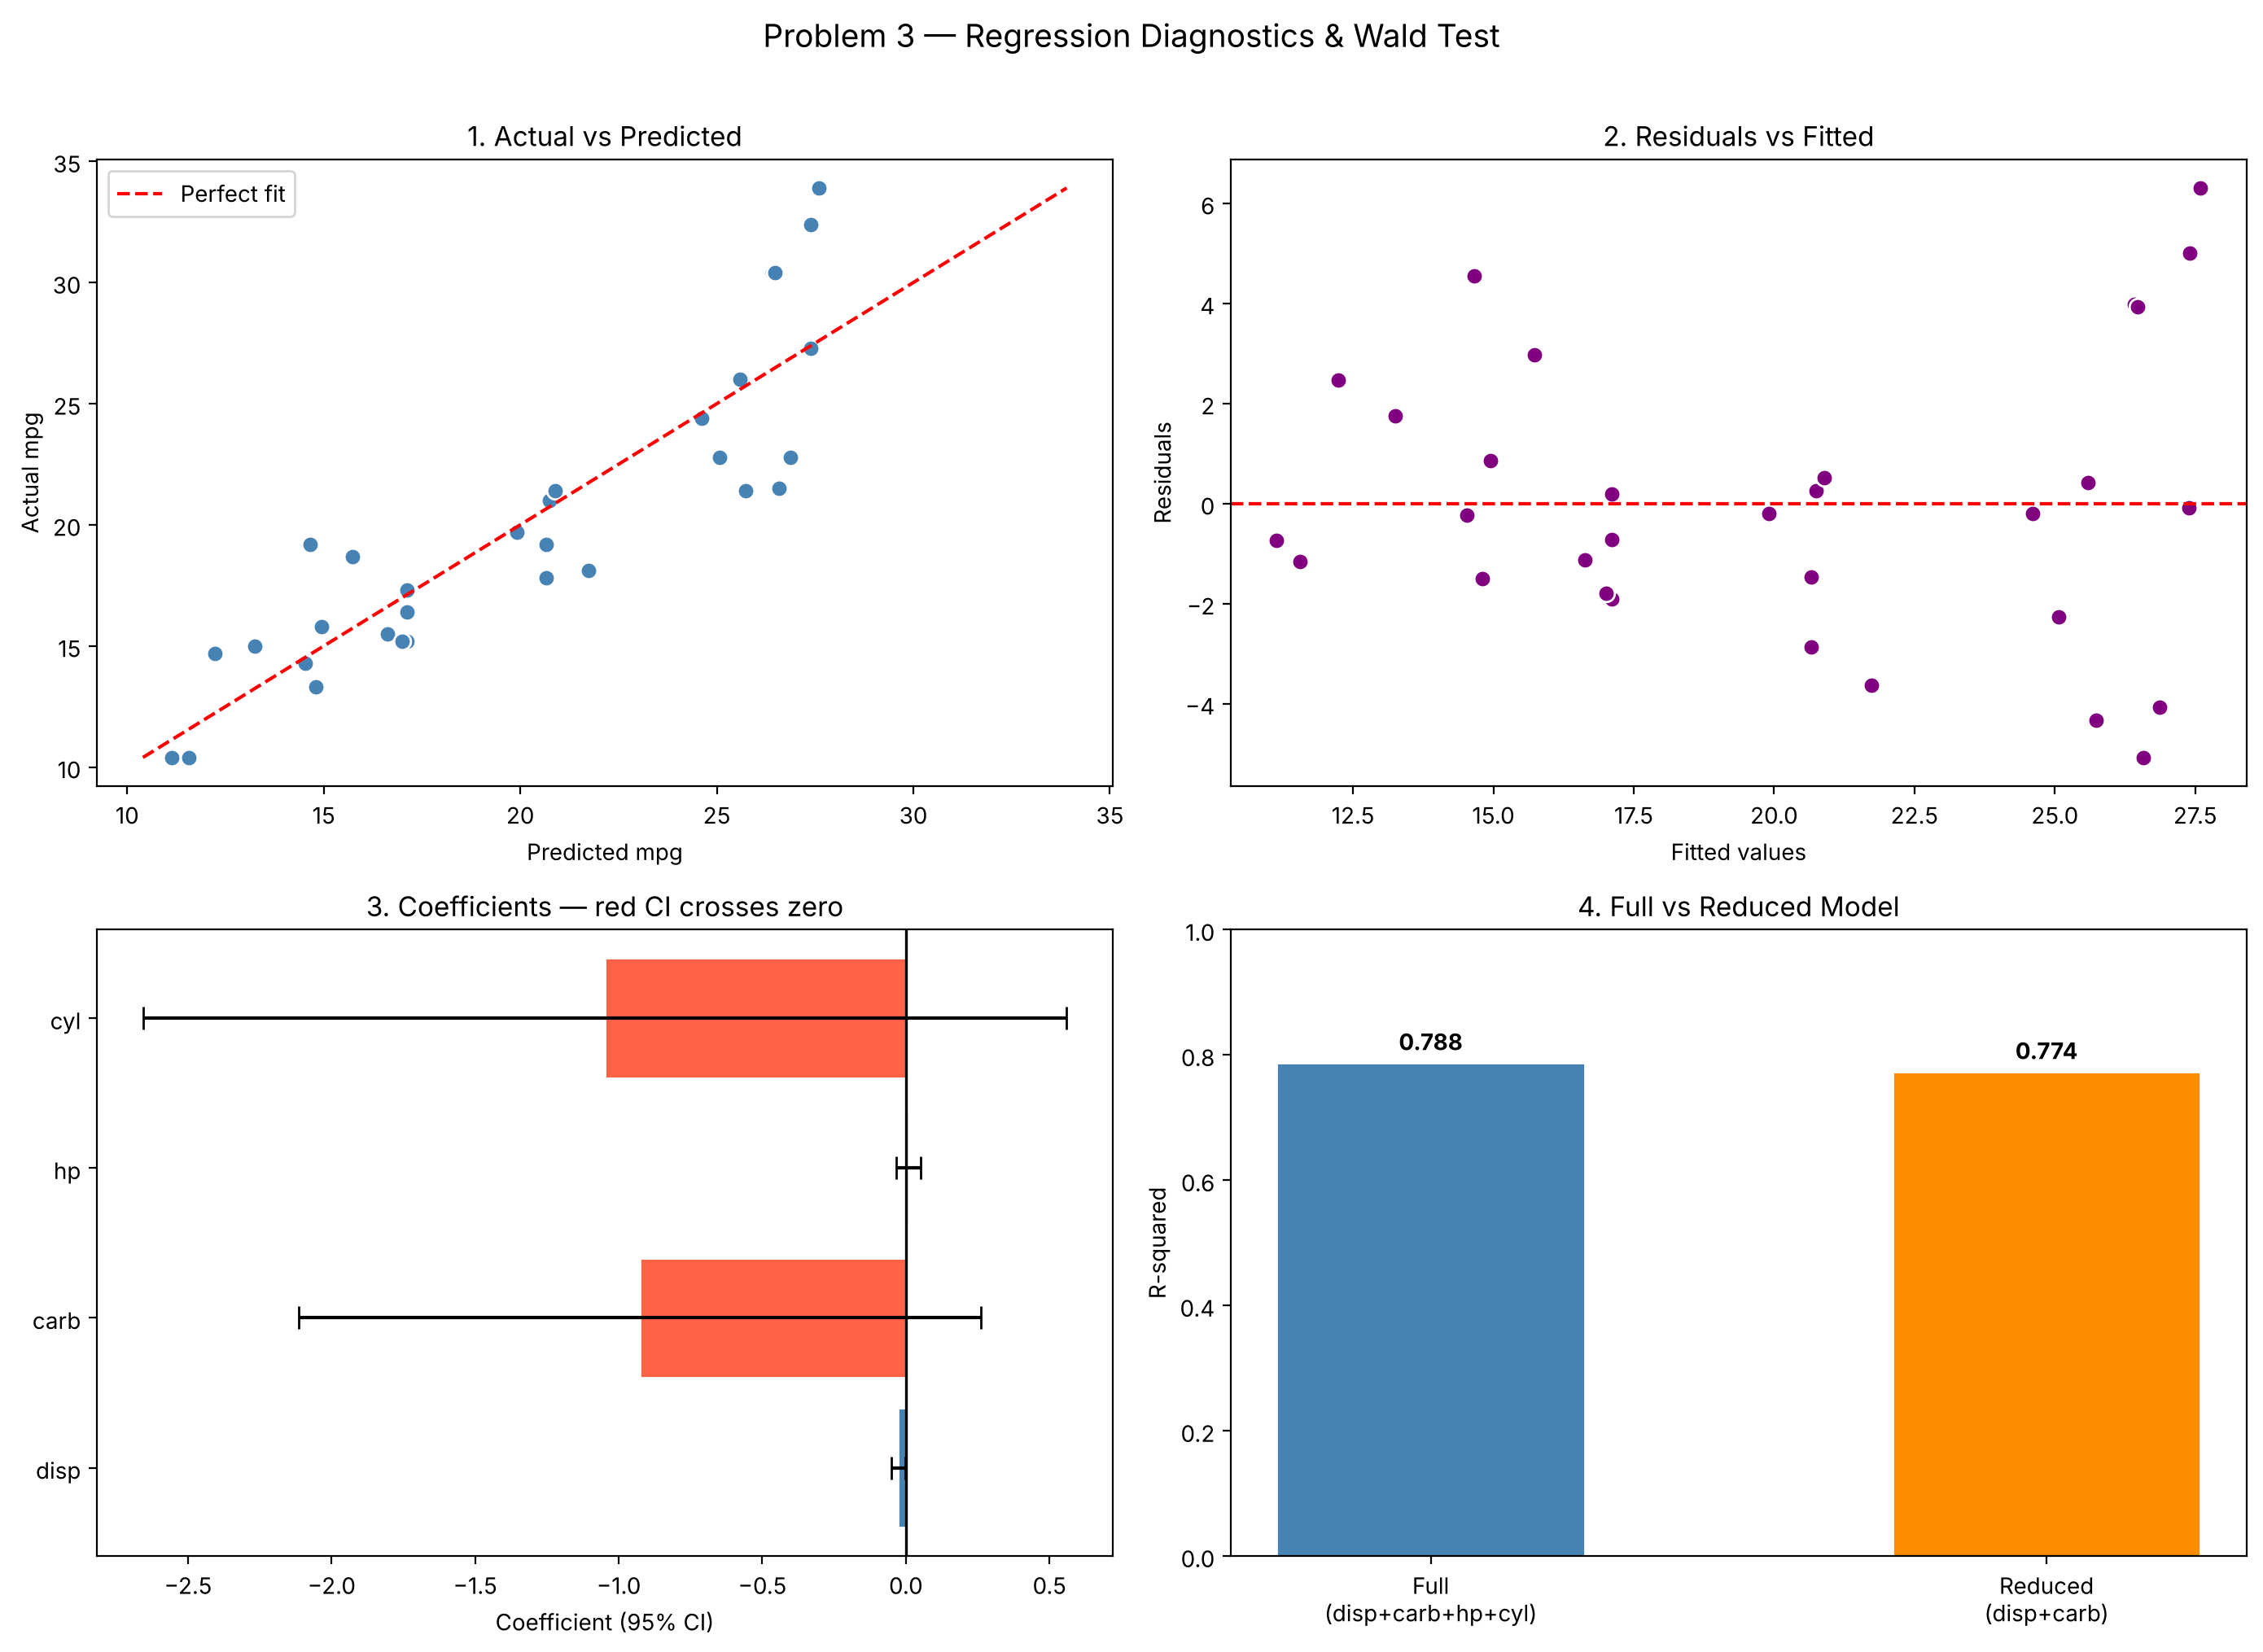

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1 Actual vs Predicted (full model)
pred_full = results_ols.fittedvalues
axes[0,0].scatter(pred_full, df['mpg'], s=55, color='steelblue', edgecolors='white')
axes[0,0].plot([df.mpg.min(), df.mpg.max()], [df.mpg.min(), df.mpg.max()],
               'r--', lw=1.5, label='Perfect fit')
axes[0,0].set(xlabel='Predicted mpg', ylabel='Actual mpg', title='1. Actual vs Predicted')
axes[0,0].legend()

# 2 Residuals vs Fitted
axes[0,1].scatter(pred_full, results_ols.resid, s=55, color='purple', edgecolors='white')
axes[0,1].axhline(0, color='red', ls='--', lw=1.5)
axes[0,1].set(xlabel='Fitted values', ylabel='Residuals', title='2. Residuals vs Fitted')

# 3 Coefficients with 95% CI - the visual Wald test
params = results_ols.params.drop('Intercept')
ci = results_ols.conf_int().drop('Intercept')
err = [params - ci[0], ci[1] - params]
cols = ['tomato' if (ci.loc[i,0] <= 0 <= ci.loc[i,1]) else 'steelblue' for i in params.index]
axes[1,0].barh(params.index, params.values, xerr=err, color=cols,
               edgecolor='white', capsize=5)
axes[1,0].axvline(0, color='black', lw=1.2)
axes[1,0].set(xlabel='Coefficient (95% CI)', title='3. Coefficients — red CI crosses zero')

# 4 Model comparison
axes[1,1].bar(['Full\n(disp+carb+hp+cyl)','Reduced\n(disp+carb)'],
              [results_ols.rsquared, reduced.rsquared],
              color=['steelblue','darkorange'], edgecolor='white', width=0.5)
axes[1,1].set(ylabel='R-squared', title='4. Full vs Reduced Model', ylim=[0,1])
for i, v in enumerate([results_ols.rsquared, reduced.rsquared]):
    axes[1,1].text(i, v+0.02, f'{v:.3f}', ha='center', fontweight='bold')

plt.suptitle('Problem 3 — Regression Diagnostics & Wald Test', fontsize=14, y=1.01)
plt.tight_layout(); plt.show()

**Reading the four plots**

**1. Actual vs predicted.** Points track the 45° line closely, consistent with R² ≈ 0.79. The Toyota Corolla and Fiat 128 sit above the line (residuals of about +6 and +5 mpg): the model under-predicts the most fuel-efficient cars.

**2. Residuals vs fitted.** The residuals scatter around zero without a strong funnel, so constant variance looks broadly acceptable. A mild curve at the extremes hints that the true mpg–displacement relationship is slightly non-linear.

**3. Coefficients with 95% confidence intervals.** This is the Wald logic made visual. Bars are red when the interval crosses zero, meaning the coefficient is not distinguishable from zero. `hp` and `cyl` both cross zero, which is consistent with the joint test (p = 0.41). Only `disp` is clear of zero.

**4. Full vs reduced model.** R² barely moves when `hp` and `cyl` are removed. Two predictors are doing the work of four.

## Step 7 — Business Interpretation & Suggestions

### What the analysis shows

**1. `hp` and `cyl` can be dropped together (Wald p = 0.414).**
The reduced model has nearly the same R² with half the predictors.

**2. Displacement is the only individually significant predictor (p = 0.025).**
Each extra cubic inch lowers mpg by about 0.027, so an engine 100 cu in larger costs roughly 2.7 mpg.

**3. Multicollinearity distorts the full model (condition number ≈ 1,510).**
`disp`, `hp` and `cyl` all measure engine size. The implausible positive `hp` coefficient is the clearest symptom.

**4. The joint test matters more than individual p-values.**
Individually, three of the four predictors looked insignificant. Only the joint test shows that `hp` and `cyl` are safe to remove as a pair.

### Recommendations

1. **Use the reduced model (`mpg ~ disp + carb`).** It is simpler, more stable, avoids the sign-flip problem and loses very little explanatory power.
2. **Collect one engine-size measure, not three.** `disp`, `hp` and `cyl` are largely redundant, so standardising on displacement would cut data-collection cost at little analytical loss.
3. **Run a joint test before dropping correlated variables.** Removing them one at a time on individual p-values risks the wrong conclusion.
4. **Report the condition number alongside R².** A value near 1,500 warns that individual coefficients shouldn't be over-interpreted.
5. **Consider `wt` (weight) next.** In the full mtcars data, weight is the strongest single predictor of mpg and was not part of this specification.

## Step 8 — Conclusion

The Wald test gives a formal, defensible basis for simplifying a model.

| Test | Result | Decision |
|------|--------|----------|
| H₀ | coef(hp) = 0 **and** coef(cyl) = 0 | n/a |
| F-statistic | 0.911 | n/a |
| p-value | **0.414** | p ≥ 0.05, so fail to reject H₀ |
| Action | Drop `hp` and `cyl` | Reduced model preferred |

| Model | Predictors | R² | Adj. R² | AIC |
|-------|-----------|-----|---------|-----|
| Full | disp, carb, hp, cyl | 0.788 | 0.757 | 165.1 |
| **Reduced** | **disp, carb** | 0.774 | 0.758 | **163.2** |

### Conclusion

Horsepower and cylinder count add nothing beyond what displacement and carburettors already capture. Dropping both gives a more parsimonious, more stable model with essentially the same explanatory power (and a lower AIC).

More broadly, this is why joint hypothesis tests matter when predictors are correlated: individual t-tests can mislead, while the Wald test evaluates variables as a group.

**Note on the sample:** an earlier version of this analysis used only 8 of the 32 rows, which left 3 residual degrees of freedom and a different p-value (about 0.325). This version uses all 32 rows (27 residual degrees of freedom). The conclusion is the same, but it now rests on a sample large enough to trust.
